# Predicting Student Health Risk - Öğrenci Sağlık Riski Tahmini

Bu projede Kaggle Playground Series S6E7 yarışmasındaki uyku, nabız, BMI, adım sayısı gibi yaşam tarzı bilgilerinden bir öğrencinin sağlık durumunu tahmin edeceğiz.Bu bir sınıflandırma problemidir.

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import joblib
import warnings
warnings.filterwarnings('ignore')

In [2]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import balanced_accuracy_score, classification_report, confusion_matrix

In [3]:
train = pd.read_csv('train.csv')
test = pd.read_csv('test.csv')

In [4]:
train.shape, test.shape

((690088, 15), (295753, 14))

In [5]:
train.head()

,id,health_condition,sleep_duration,heart_rate,bmi,calorie_expenditure,step_count,exercise_duration,water_intake,diet_type,stress_level,sleep_quality,physical_activity_level,smoking_alcohol,gender
0,0,unhealthy,5.22,70.6,25.66,2174.0,1326.0,19.8,1.86,veg,high,average,sedentary,yes,female
1,1,at-risk,5.53,71.3,25.84,1966.0,9891.0,49.9,1.26,non-veg,low,average,moderate,yes,other
2,2,unhealthy,5.29,75.4,24.54,2688.0,14216.0,38.1,1.60,veg,high,poor,active,yes,male
3,3,unhealthy,4.70,77.2,23.13,2630.0,7174.0,59.9,2.02,veg,high,average,active,occasional,female
4,4,at-risk,7.23,73.4,28.44,2560.0,6584.0,46.0,2.25,veg,NaN,average,sedentary,NaN,male


In [6]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 690088 entries, 0 to 690087
Data columns (total 15 columns):
 #   Column                   Non-Null Count   Dtype  
---  ------                   --------------   -----  
 0   id                       690088 non-null  int64  
 1   health_condition         690088 non-null  object 
 2   sleep_duration           614089 non-null  float64
 3   heart_rate               682255 non-null  float64
 4   bmi                      676190 non-null  float64
 5   calorie_expenditure      637235 non-null  float64
 6   step_count               676172 non-null  float64
 7   exercise_duration        683187 non-null  float64
 8   water_intake             646611 non-null  float64
 9   diet_type                683187 non-null  object 
 10  stress_level             607277 non-null  object 
 11  sleep_quality            631757 non-null  object 
 12  physical_activity_level  653467 non-null  object 
 13  smoking_alcohol          661506 non-null  object 
 14  gend

In [7]:
train.describe()

,id,sleep_duration,heart_rate,bmi,calorie_expenditure,step_count,exercise_duration,water_intake
count,690088.00000,614089.000000,682255.000000,676190.000000,637235.000000,676172.000000,683187.000000,646611.000000
mean,345043.50000,6.992597,75.096504,22.984925,2226.084931,8615.953050,38.751456,2.188542
std,199211.39062,1.215407,8.175106,2.481787,347.532098,3929.399831,14.742189,0.518489
min,0.00000,3.000000,50.000000,16.000000,1200.000000,1002.000000,0.000000,0.500000
25%,172521.75000,6.160000,69.400000,21.320000,2053.000000,5389.000000,29.200000,1.840000
50%,345043.50000,6.990000,75.100000,22.990000,2241.000000,8856.000000,39.400000,2.170000
75%,517565.25000,7.810000,80.700000,24.660000,2456.000000,12114.000000,49.400000,2.500000
max,690087.00000,10.000000,107.700000,34.820000,3580.000000,14999.000000,99.800000,4.720000


In [8]:
# eksik değer oranları (%)
(train.isnull().mean() * 100).round(1)

id                          0.0
health_condition            0.0
sleep_duration             11.0
heart_rate                  1.1
bmi                         2.0
calorie_expenditure         7.7
step_count                  2.0
exercise_duration           1.0
water_intake                6.3
diet_type                   1.0
stress_level               12.0
sleep_quality               8.5
physical_activity_level     5.3
smoking_alcohol             4.1
gender                      3.1
dtype: float64

In [9]:
train['health_condition'].value_counts()

health_condition
at-risk      592561
unhealthy     57724
fit           39803
Name: count, dtype: int64

<Axes: xlabel='health_condition', ylabel='count'>

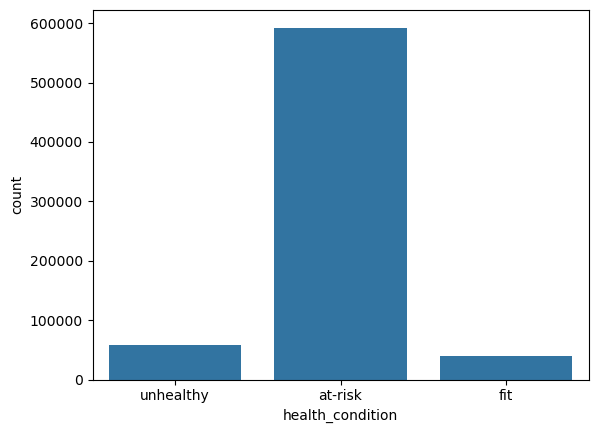

In [10]:
sns.countplot(x='health_condition', data=train)

<Axes: >

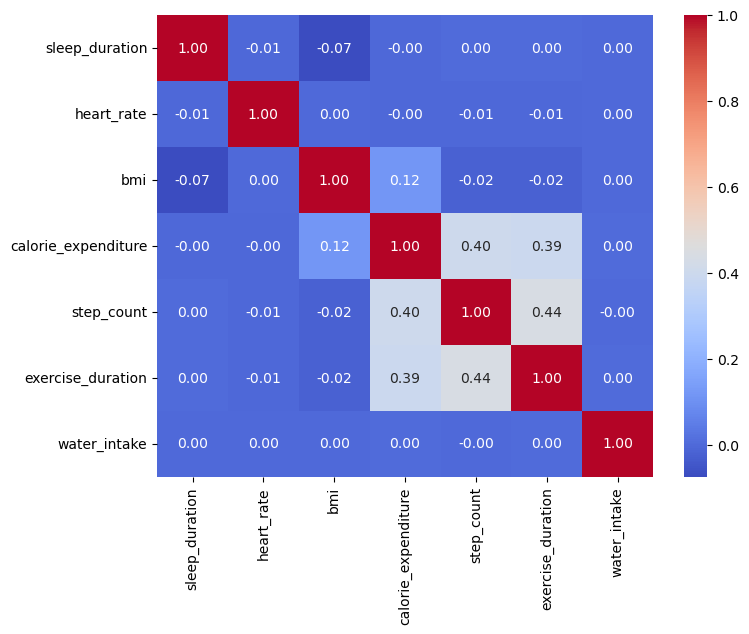

In [11]:
# sayısal sütunların korelasyonu
plt.figure(figsize=(8,6))
sns.heatmap(train.drop('id', axis=1).select_dtypes('number').corr(), annot=True, fmt='.2f', cmap='coolwarm')

In [12]:
train['health_condition'] = train['health_condition'].map({'fit':0, 'at-risk':1, 'unhealthy':2})

In [13]:
x = train.drop(['id','health_condition'], axis=1)
y = train['health_condition']
x_test = test.drop('id', axis=1)

In [14]:
kat = x.select_dtypes('object').columns.tolist()
say = [c for c in x.columns if c not in kat]
kat

['diet_type',
 'stress_level',
 'sleep_quality',
 'physical_activity_level',
 'smoking_alcohol',
 'gender']

In [15]:
# eksikleri doldur: kategorik -> 'missing', sayısal -> medyan; sonra One-Hot ve StandardScaler
def on():
    return ColumnTransformer([
        ('kat', make_pipeline(SimpleImputer(strategy='constant', fill_value='missing'), OneHotEncoder(handle_unknown='ignore')), kat),
        ('say', make_pipeline(SimpleImputer(strategy='median'), StandardScaler()), say)])

In [16]:
x_train, x_val, y_train, y_val = train_test_split(x, y, test_size=.2, random_state=42, stratify=y)

In [17]:
L = make_pipeline(on(), LogisticRegression(max_iter=500, class_weight='balanced'))
L.fit(x_train, y_train)

,steps,"[('columntransformer', ...), ('logisticregression', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('kat', ...), ('say', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [18]:
r = make_pipeline(on(), RandomForestClassifier(n_estimators=100, class_weight='balanced', n_jobs=-1, random_state=42))
r.fit(x_train, y_train)

,steps,"[('columntransformer', ...), ('randomforestclassifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('kat', ...), ('say', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [19]:
b = make_pipeline(on(), HistGradientBoostingClassifier(class_weight='balanced', random_state=42))
b.fit(x_train, y_train)

,steps,"[('columntransformer', ...), ('histgradientboostingclassifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('kat', ...), ('say', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [20]:
karsilastirma = pd.DataFrame({
    'Model': ['LogisticRegression', 'RandomForest', 'HistGradientBoosting'],
    'Balanced Accuracy': [balanced_accuracy_score(y_val, m.predict(x_val)) for m in (L, r, b)]})
karsilastirma

,Model,Balanced Accuracy
0,LogisticRegression,0.898832
1,RandomForest,0.866227
2,HistGradientBoosting,0.949432


In [21]:
tahmin = b.predict(x_val)
print(classification_report(y_val, tahmin, target_names=['fit','at-risk','unhealthy']))
confusion_matrix(y_val, tahmin)

              precision    recall  f1-score   support

         fit       0.73      0.95      0.83      7961
     at-risk       0.99      0.93      0.96    118512
   unhealthy       0.69      0.97      0.80     11545

    accuracy                           0.94    138018
   macro avg       0.80      0.95      0.86    138018
weighted avg       0.95      0.94      0.94    138018



array([[  7545,    367,     49],
       [  2732, 110750,   5030],
       [    50,    342,  11153]])

In [22]:
# en iyi model hangisiyse onu tüm train ile eğit (burada HistGradientBoosting)
model = make_pipeline(on(), HistGradientBoostingClassifier(class_weight='balanced', random_state=42))
model.fit(x, y)

,steps,"[('columntransformer', ...), ('histgradientboostingclassifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('kat', ...), ('say', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [23]:
tahmin = model.predict(x_test)
sonuc = pd.DataFrame({'id': test['id'], 'health_condition': pd.Series(tahmin).map({0:'fit', 1:'at-risk', 2:'unhealthy'})})
sonuc.to_csv('sonuc1.csv', index=False)
sonuc.head()

,id,health_condition
0,690088,unhealthy
1,690089,unhealthy
2,690090,at-risk
3,690091,at-risk
4,690092,unhealthy


In [24]:
# Streamlit uygulaması bu iki dosyayı kullanacak
joblib.dump(model, 'health_model.pkl')
train.drop(['id','health_condition'], axis=1).sample(5000, random_state=42).to_csv('ornek.csv', index=False)

## Sonuç

Bu projede yaşam tarzı bilgilerinden öğrencinin sağlık durumunu tahmin ettik. Veride her sütunda eksik değer vardı ve sınıflar dengesizdi (çoğunluk `at-risk`). Eksikleri medyan / 'missing' ile doldurduk, `class_weight='balanced'` kullandık ve üç modeli (Logistic Regression, Random Forest, HistGradientBoosting) **balanced accuracy** ile karşılaştırdık (tablo yukarıda).
En iyi modeli tüm train verisiyle eğitip `sonuc1.csv` dosyasını Kaggle'a gönderdik, aynı modeli `health_model.pkl` olarak kaydedip `app.py` ile Streamlit uygulamasına bağladık.